# Cookie Cats: gate_30 or gate_40

Players were randomly assigned to a gate after 30 rounds or after 40 rounds.
The planned split is not in the file. The comparison still uses every assigned player.
`retention_1` means the player came back the day after install.
`retention_7` means the player came back 7 days after install.
`sum_gamerounds` is how many rounds the player played during the measured period.

## 1. Load and first look

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

GATE_30 = "#1F4E5F"
GATE_40 = "#8AA0B2"

def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D9E2EC")
    ax.spines["bottom"].set_color("#D9E2EC")
    ax.tick_params(length=0)
    ax.grid(axis="y", color="#EEF2F6", linewidth=0.8)
    ax.set_axisbelow(True)

def label_bars(ax):
    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=8,
            color="#102A43",
            xytext=(0, 2),
            textcoords="offset points",
        )

df = pd.read_csv("cookie_cats.csv")
df.shape

(90189, 5)

In [ ]:
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


90,189 players, one row per player.
`version` is the gate the player was assigned to. It does not mean the player reached that gate.

## 2. Data checks

In [ ]:
df.isna().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [ ]:
df.dtypes

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

In [ ]:
df["userid"].duplicated().sum()

np.int64(0)

In [ ]:
df["version"].value_counts()

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [ ]:
from scipy.stats import chisquare

version_counts = df["version"].value_counts().reindex(["gate_30", "gate_40"])
version_share = (version_counts / version_counts.sum() * 100).round(1)
chi_srm, p_srm = chisquare(version_counts)

print(version_counts.to_string())
print(version_share.to_string())
print("If the planned split was exactly 50/50, p =", round(p_srm, 4))

version
gate_30    44700
gate_40    45489
version
gate_30    49.6
gate_40    50.4
If the planned split was exactly 50/50, p = 0.0086


In [ ]:
(df["sum_gamerounds"] < 0).sum()

np.int64(0)

In [ ]:
(df["sum_gamerounds"] == 0).sum()

np.int64(3994)

In [ ]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [ ]:
df.nlargest(5, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


Rounds are capped at 100 in this chart so the player with 49,854 rounds does not squash everyone else into one bar. The dashed lines are the two gates.

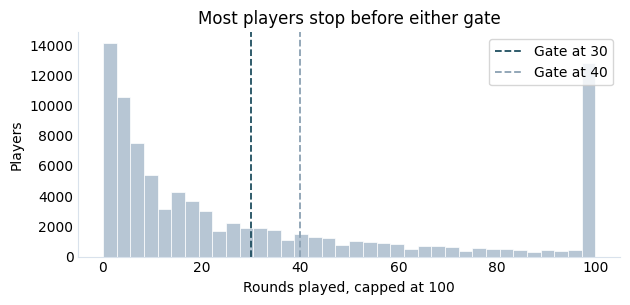

In [ ]:
rounds_capped = df["sum_gamerounds"].clip(upper=100)
fig, ax = plt.subplots(figsize=(6.4, 3.15))
ax.hist(rounds_capped, bins=36, color="#B7C6D4", edgecolor="white", linewidth=0.5)
ax.axvline(30, color=GATE_30, linestyle="--", linewidth=1.3, label="Gate at 30")
ax.axvline(40, color=GATE_40, linestyle="--", linewidth=1.3, label="Gate at 40")
ax.set_xlabel("Rounds played, capped at 100")
ax.set_ylabel("Players")
ax.set_title("Most players stop before either gate")
style_axis(ax)
ax.grid(False)
ax.legend()
fig.tight_layout()
plt.show()

Summary of the checks:

- No missing values.
- No duplicate `userid`. Each player appears once.
- The split is close to even: 44,700 players in `gate_30` (49.6%) and 45,489 in `gate_40` (50.4%). The planned allocation is not in this file, so it is unknown whether the gap of 789 players was intended. If the plan was exactly 50/50, the check above gives `p ≈ 0.0086`. With about 90,000 players, a small departure from half and half can reach that p-value. This is a limitation. The retention comparison still uses every assigned player.
- No negative rounds. 3,994 players have 0 rounds: they installed and did not play. That is valid.
- One player played 49,854 rounds, in `gate_30`. Without that player, the average is 51.3 rounds in both versions. The median is 17 rounds in `gate_30` and 16 in `gate_40`. The decision below uses retention, not the average number of rounds.
- There is no column that says "passed the gate". The chart shows that most players are to the left of both gates.

## 3. Who came back

`returned` counts players whose retention value is `True`. `did_not_return` counts players whose retention value is `False`.
A player who did not return on one of these days may still return on another day.
The percentage is the number who returned divided by all players assigned to that version.

,players,returned_day_1,did_not_return_day_1,returned_day_1_pct,returned_day_7,did_not_return_day_7,returned_day_7_pct
version,,,,,,,
gate_30,44700,20034,24666,44.8,8502,36198,19.0
gate_40,45489,20119,25370,44.2,8279,37210,18.2


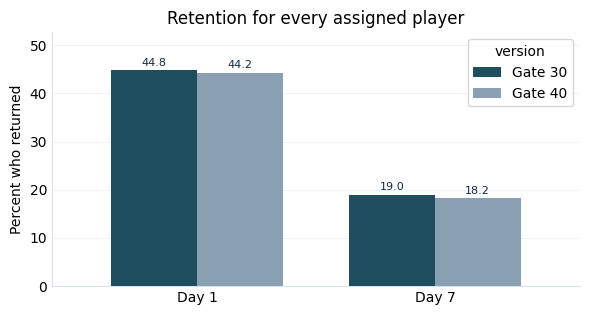

In [ ]:
summary = (
    df.groupby("version", sort=False)
    .agg(
        players=("userid", "size"),
        returned_day_1=("retention_1", "sum"),
        returned_day_7=("retention_7", "sum"),
    )
    .reindex(["gate_30", "gate_40"])
)
summary["did_not_return_day_1"] = summary["players"] - summary["returned_day_1"]
summary["did_not_return_day_7"] = summary["players"] - summary["returned_day_7"]
summary["returned_day_1_pct"] = (summary["returned_day_1"] / summary["players"] * 100).round(1)
summary["returned_day_7_pct"] = (summary["returned_day_7"] / summary["players"] * 100).round(1)
summary = summary[
    [
        "players",
        "returned_day_1",
        "did_not_return_day_1",
        "returned_day_1_pct",
        "returned_day_7",
        "did_not_return_day_7",
        "returned_day_7_pct",
    ]
]

from IPython.display import display

display(summary)

fig, ax = plt.subplots(figsize=(6.0, 3.25))
plot_data = summary[["returned_day_1_pct", "returned_day_7_pct"]].T
plot_data.index = ["Day 1", "Day 7"]
plot_data = plot_data.rename(columns={"gate_30": "Gate 30", "gate_40": "Gate 40"})
plot_data.plot(kind="bar", ax=ax, color=[GATE_30, GATE_40], width=0.72, zorder=3)
ax.set_xlabel("")
ax.set_ylabel("Percent who returned")
ax.set_title("Retention for every assigned player")
ax.tick_params(axis="x", rotation=0)
style_axis(ax)
label_bars(ax)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
fig.tight_layout()
plt.show()

After one day, 44.8% returned in `gate_30` and 44.2% returned in `gate_40`.
After a week, 19.0% returned in `gate_30` and 18.2% returned in `gate_40`.

`gate_30` is higher on both measures. The week gap is about 8 extra players returning out of every 1,000. The bars look close because the gap is small. Section 4 calculates the gap and explains the numbers.

## 4. The gap between the gates

### The calculation

The code subtracts the `gate_40` return rate from the `gate_30` return rate.

In [ ]:
import math

from scipy.stats import chi2_contingency, norm

def proportion_difference(success_a, n_a, success_b, n_b):
    p_a = success_a / n_a
    p_b = success_b / n_b
    diff = p_a - p_b
    se = math.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    z = norm.ppf(0.975)
    return diff, diff - z * se, diff + z * se

counts_day_1 = pd.crosstab(df["version"], df["retention_1"])
chi2, p_day_1, dof, expected = chi2_contingency(counts_day_1)

counts_day_7 = pd.crosstab(df["version"], df["retention_7"])
chi2, p_day_7, dof, expected = chi2_contingency(counts_day_7)

diff_day_1, low_day_1, high_day_1 = proportion_difference(
    summary.loc["gate_30", "returned_day_1"],
    summary.loc["gate_30", "players"],
    summary.loc["gate_40", "returned_day_1"],
    summary.loc["gate_40", "players"],
)
diff_day_7, low_day_7, high_day_7 = proportion_difference(
    summary.loc["gate_30", "returned_day_7"],
    summary.loc["gate_30", "players"],
    summary.loc["gate_40", "returned_day_7"],
    summary.loc["gate_40", "players"],
)

print(counts_day_1)
print(
    "day 1: difference",
    round(diff_day_1 * 100, 1),
    "percentage points; 95% CI",
    round(low_day_1 * 100, 1),
    "to",
    round(high_day_1 * 100, 1),
    "; p =",
    round(p_day_1, 4),
)
print(counts_day_7)
print(
    "day 7: difference",
    round(diff_day_7 * 100, 1),
    "percentage points; 95% CI",
    round(low_day_7 * 100, 1),
    "to",
    round(high_day_7 * 100, 1),
    "; p =",
    round(p_day_7, 4),
)

retention_1  False  True 
version                  
gate_30      24666  20034
gate_40      25370  20119
day 1: difference 0.6 percentage points; 95% CI -0.1 to 1.2 ; p = 0.0755
retention_7  False  True 
version                  
gate_30      36198   8502
gate_40      37210   8279
day 7: difference 0.8 percentage points; 95% CI 0.3 to 1.3 ; p = 0.0016


### What the numbers mean

The code above uses every assigned player, because that is the random split.

After a week, 19.0% returned in `gate_30` and 18.2% returned in `gate_40`. The gap is 19.0 minus 18.2, which is 0.8 percentage points: about 8 extra returning players per 1,000 in `gate_30`.

The 95% interval is a margin around that 8. Another sample of players would give a gap a little above 8 or a little below 8. With about 45,000 players in each gate, the gap can shift by about 5 players per 1,000 either way. 95% is the usual width of that margin: if the sample were drawn many times, a margin built this way would catch the real gap about 95 times in 100.

- 8 − 5 = 3 extra players per 1,000
- 8 + 5 = 13 extra players per 1,000

In percentage points the margin is 0.3 to 1.3. Both 3 and 13 are still more players coming back in `gate_30`.

`p` asks a second question: if the gate made no difference, how often would luck alone make a gap this large? Above 0.05, the gap can still be luck. Below 0.05, luck is an unlikely explanation. On day 7, `p = 0.0016`, about 2 times in 1,000. That is below 0.05.

On day 1 the gap is about 6 extra players per 1,000. The margin runs from −0.1 to 1.2 percentage points and includes the same return rate in both gates. `p = 0.0755`, about 8 times in 100, which is above 0.05. Day 1 alone is not enough. The direction is still toward `gate_30`.

## 5. Conclusion

On retention, the evidence supports keeping the gate at 30, based on day 7. That choice was made after seeing the results. Players clearly prefer the gate after 30 rounds. Day 1 alone is not enough.

### A possible explanation

The file shows who came back. It does not show why. One hypothesis to test is that an earlier stop leaves players wanting to come back, so more of them return a week later. They have not finished the game yet, and they are curious about what comes next.

### What to investigate next

- How many players reached the gate, how long they waited, and how much they paid to skip the wait. This file has none of those.
- This file has no purchases or revenue. `gate_40` can keep fewer players and still make more money, or the other way around. If the business goal is money, retention alone cannot decide the move.
- `sum_gamerounds` has one player with 49,854 rounds. If rounds played becomes a metric, look at the median as well as the mean.
- `retention_1` and `retention_7` are counted from the install day, not from the moment the player reached the gate. Measuring "came back after the gate" needs a timestamp of reaching the gate.